<a href="https://colab.research.google.com/github/Lynniez/Machine-learning-TP3-DJEBOURI-Lynda/blob/main/tp3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

(10, 2)
       Study Hours  Exam Score
count     10.00000   10.000000
mean       5.50000   67.900000
std        3.02765   16.907921
min        1.00000   42.000000
25%        3.25000   56.000000
50%        5.50000   68.000000
75%        7.75000   80.250000
max       10.00000   91.000000


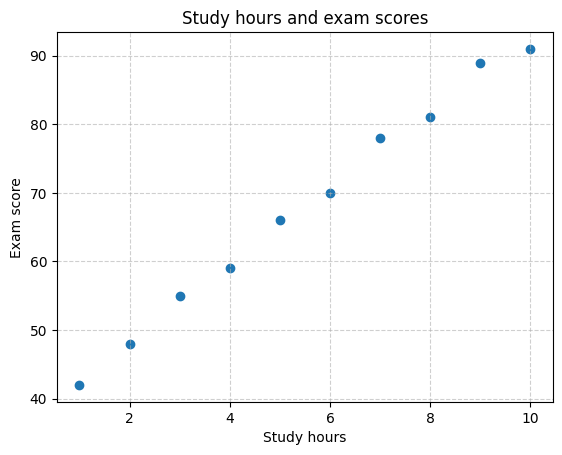

(10, 1) (10,)


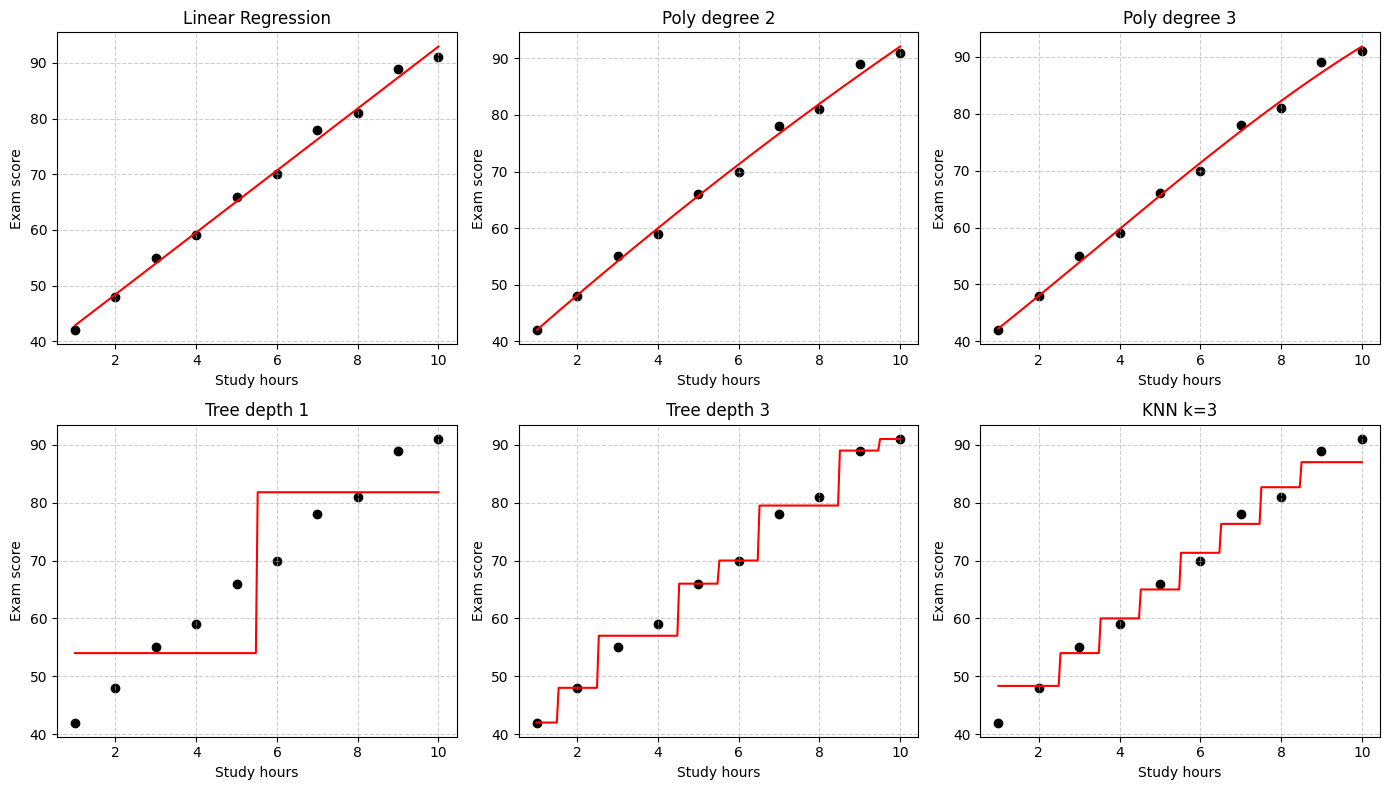

               Model  Training RMSE  Training R2
0  Linear Regression         1.1672       0.9947
1      Poly degree 2         1.0435       0.9958
2      Poly degree 3         1.0211       0.9959
3       Tree depth 1         8.0050       0.7509
4       Tree depth 3         1.1180       0.9951
5            KNN k=3         2.6562       0.9726
Number of iterations: 10
Iteration 1 | train: [1, 2, 3, 4, 5, 6, 7, 8, 9] | test: [0]
Iteration 2 | train: [0, 2, 3, 4, 5, 6, 7, 8, 9] | test: [1]
Iteration 3 | train: [0, 1, 3, 4, 5, 6, 7, 8, 9] | test: [2]
Iteration 4 | train: [0, 1, 2, 4, 5, 6, 7, 8, 9] | test: [3]
Iteration 5 | train: [0, 1, 2, 3, 5, 6, 7, 8, 9] | test: [4]
Iteration 6 | train: [0, 1, 2, 3, 4, 6, 7, 8, 9] | test: [5]
Iteration 7 | train: [0, 1, 2, 3, 4, 5, 7, 8, 9] | test: [6]
Iteration 8 | train: [0, 1, 2, 3, 4, 5, 6, 8, 9] | test: [7]
Iteration 9 | train: [0, 1, 2, 3, 4, 5, 6, 7, 9] | test: [8]
Iteration 10 | train: [0, 1, 2, 3, 4, 5, 6, 7, 8] | test: [9]
   Polynomial Degree 

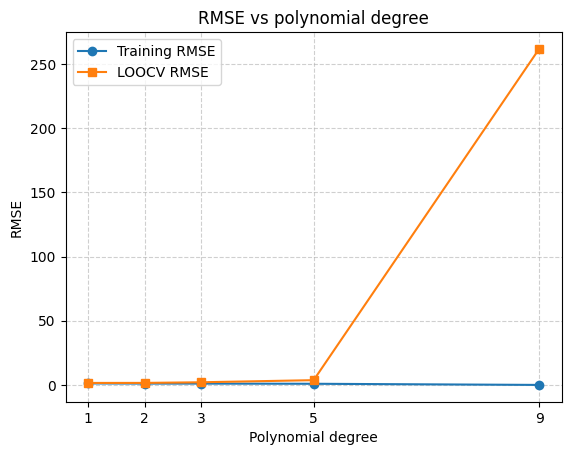

Degree 1 - LOOCV RMSE: 1.5486
Degree 3 - LOOCV RMSE: 2.062
Degree 5 - LOOCV RMSE: 3.707
   alpha  Ridge LOOCV RMSE  Lasso LOOCV RMSE
0   0.01            2.1442            1.7654
1   0.10            1.8071            1.6223
2   1.00            3.5735            1.9187
3  10.00            7.2820           11.8773
Best alpha Ridge: 0.1 | Best alpha Lasso: 0.1


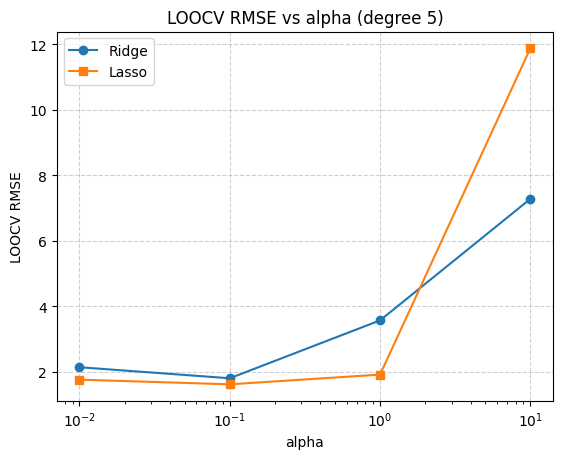

                   Model Feature Degree Regularization  LOOCV RMSE
0      Linear Regression              1           None      1.5486
1  Polynomial Regression              3           None      2.0620
2  Polynomial Regression              5           None      3.7070
3       Ridge Regression              5             L2      1.8071
4       Lasso Regression              5             L1      1.6223
5  Decision Tree depth 1              -           None     13.4583
6  Decision Tree depth 3              -           None      6.3659
7              KNN k = 3              -           None      6.0037


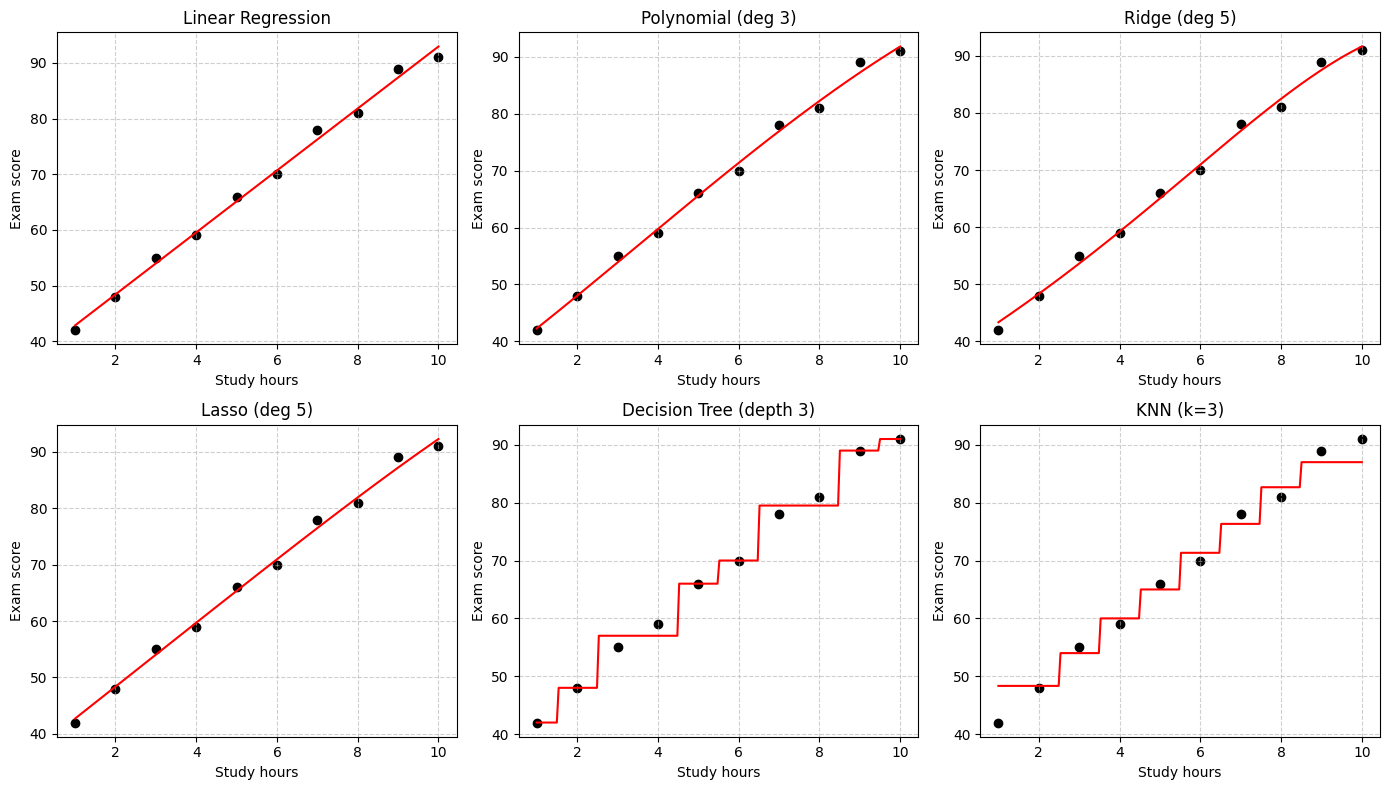

                     Model  Training RMSE  LOOCV RMSE
0        Linear Regression         1.1672      1.5486
1       Polynomial (deg 3)         1.0211      2.0620
2            Ridge (deg 5)         1.0865      1.8071
3            Lasso (deg 5)         1.0656      1.6223
4  Decision Tree (depth 3)         1.1180      6.3659
5                KNN (k=3)         2.6562      6.0037
Best model: Linear Regression


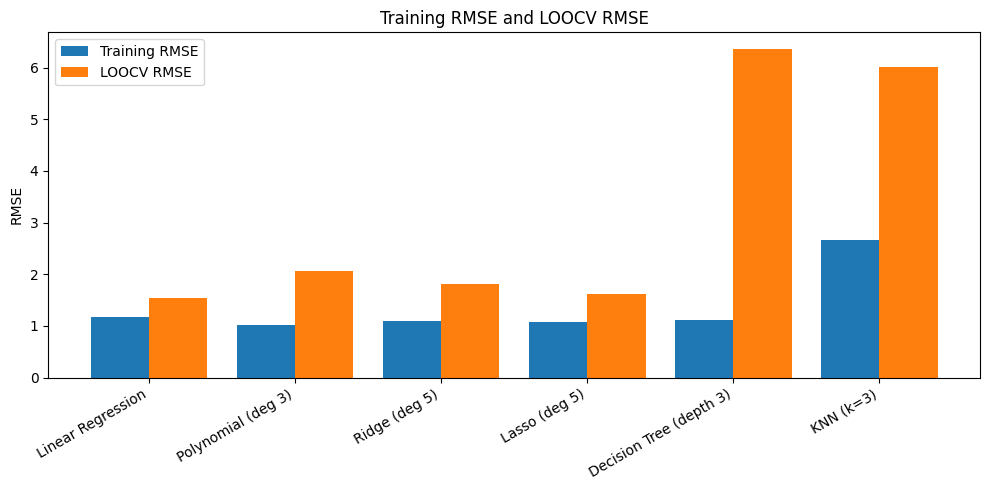

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import LeaveOneOut, cross_val_score
from sklearn.metrics import mean_squared_error, r2_score
import warnings
warnings.filterwarnings("ignore")



# Part A : Exploring different hypothesis spaces


df = pd.DataFrame({
    "Study Hours": [1,2,3,4,5,6,7,8,9,10],
    "Exam Score":    [42,48,55,59,66,70,78,81,89,91],
}, index=["S1", "S2", "S3", "S4", "S5", "S6","S7","S8", "S9", "S10"])

print(df.shape)
print(df.describe())

plt.scatter( df["Study Hours"] , df["Exam Score"] )
plt.title("Study hours and exam scores")
plt.xlabel("Study hours")
plt.ylabel("Exam score")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

X = df[["Study Hours"]]
y = df["Exam Score"]
print(X.shape, y.shape)

# the six models
models = {
    "Linear Regression": LinearRegression(),
    "Poly degree 2": Pipeline([("poly", PolynomialFeatures(degree=2)), ("lr", LinearRegression())]),
    "Poly degree 3": Pipeline([("poly", PolynomialFeatures(degree=3)), ("lr", LinearRegression())]),
    "Tree depth 1": DecisionTreeRegressor(max_depth=1, random_state=0),
    "Tree depth 3": DecisionTreeRegressor(max_depth=3, random_state=0),
    "KNN k=3": KNeighborsRegressor(n_neighbors=3),
}

# points used to draw the curves
x_line = pd.DataFrame({"Study Hours": np.linspace(1, 10, 200)})

plt.figure(figsize=(14, 8))
results_A = []
i = 1
for name in models:
    model = models[name]
    model.fit(X, y)
    y_pred = model.predict(X)

    rmse = np.sqrt(mean_squared_error(y, y_pred))
    r2 = r2_score(y, y_pred)
    results_A.append([name, rmse, r2])

    plt.subplot(2, 3, i)
    plt.scatter(X, y, color="black")
    plt.plot(x_line, model.predict(x_line), color="red")
    plt.title(name)
    plt.xlabel("Study hours")
    plt.ylabel("Exam score")
    plt.grid(True, linestyle='--', alpha=0.6)
    i = i + 1

plt.tight_layout()
plt.show()

table_A = pd.DataFrame(results_A, columns=["Model", "Training RMSE", "Training R2"])
print(table_A.round(4))



# Part B : Model complexity and generalization


# 1. Leave-One-Out : train and test sets
loo = LeaveOneOut()
print("Number of iterations:", loo.get_n_splits(X))

k = 1
for train_index, test_index in loo.split(X):
    print("Iteration", k, "| train:", train_index.tolist(), "| test:", test_index.tolist())
    k = k + 1
# each time, one student is the test set and the 9 others are the train set

# 2. and 3. different degrees
degrees = [1, 2, 3, 5, 9]
train_rmse_list = []
loocv_rmse_list = []

for d in degrees:
    model = Pipeline([("poly", PolynomialFeatures(degree=d)), ("lr", LinearRegression())])

    # training RMSE (fit on all the data)
    model.fit(X, y)
    train_rmse = np.sqrt(mean_squared_error(y, model.predict(X)))

    # LOOCV RMSE
    scores = cross_val_score(model, X, y, cv=LeaveOneOut(), scoring="neg_mean_squared_error")
    loocv_rmse = np.sqrt(-scores.mean())

    train_rmse_list.append(train_rmse)
    loocv_rmse_list.append(loocv_rmse)

table_B = pd.DataFrame({
    "Polynomial Degree": degrees,
    "Training RMSE": train_rmse_list,
    "LOOCV RMSE": loocv_rmse_list,
})
print(table_B.round(4))

best_degree = degrees[int(np.argmin(loocv_rmse_list))]
print("Best degree (lowest LOOCV RMSE):", best_degree)

# 4. plot
plt.plot(degrees, train_rmse_list, "o-", label="Training RMSE")
plt.plot(degrees, loocv_rmse_list, "s-", label="LOOCV RMSE")
plt.title("RMSE vs polynomial degree")
plt.xlabel("Polynomial degree")
plt.ylabel("RMSE")
plt.xticks(degrees)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()



# Part C : Feature representation and regularization


# 1. different feature representations (scaling is inside the pipeline)
loocv_poly = {}
for d in [1, 3, 5]:
    model = Pipeline([
        ("poly", PolynomialFeatures(degree=d, include_bias=False)),
        ("scaler", StandardScaler()),
        ("lr", LinearRegression()),
    ])
    scores = cross_val_score(model, X, y, cv=LeaveOneOut(), scoring="neg_mean_squared_error")
    loocv_poly[d] = np.sqrt(-scores.mean())
    print("Degree", d, "- LOOCV RMSE:", round(loocv_poly[d], 4))

# 2. Ridge and Lasso on degree 5
alphas = [0.01, 0.1, 1, 10]
ridge_rmse = []
lasso_rmse = []

for a in alphas:
    ridge = Pipeline([
        ("poly", PolynomialFeatures(degree=5, include_bias=False)),
        ("scaler", StandardScaler()),
        ("reg", Ridge(alpha=a)),
    ])
    lasso = Pipeline([
        ("poly", PolynomialFeatures(degree=5, include_bias=False)),
        ("scaler", StandardScaler()),
        ("reg", Lasso(alpha=a, max_iter=100000)),
    ])
    s1 = cross_val_score(ridge, X, y, cv=LeaveOneOut(), scoring="neg_mean_squared_error")
    s2 = cross_val_score(lasso, X, y, cv=LeaveOneOut(), scoring="neg_mean_squared_error")
    ridge_rmse.append(np.sqrt(-s1.mean()))
    lasso_rmse.append(np.sqrt(-s2.mean()))

print(pd.DataFrame({"alpha": alphas, "Ridge LOOCV RMSE": ridge_rmse, "Lasso LOOCV RMSE": lasso_rmse}).round(4))

best_alpha_ridge = alphas[int(np.argmin(ridge_rmse))]
best_alpha_lasso = alphas[int(np.argmin(lasso_rmse))]
print("Best alpha Ridge:", best_alpha_ridge, "| Best alpha Lasso:", best_alpha_lasso)

plt.plot(alphas, ridge_rmse, "o-", label="Ridge")
plt.plot(alphas, lasso_rmse, "s-", label="Lasso")
plt.xscale("log")
plt.title("LOOCV RMSE vs alpha (degree 5)")
plt.xlabel("alpha")
plt.ylabel("LOOCV RMSE")
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

# 3. LOOCV RMSE for the other models
tree1 = DecisionTreeRegressor(max_depth=1, random_state=0)
tree3 = DecisionTreeRegressor(max_depth=3, random_state=0)
knn = KNeighborsRegressor(n_neighbors=3)

s = cross_val_score(tree1, X, y, cv=LeaveOneOut(), scoring="neg_mean_squared_error")
tree1_rmse = np.sqrt(-s.mean())
s = cross_val_score(tree3, X, y, cv=LeaveOneOut(), scoring="neg_mean_squared_error")
tree3_rmse = np.sqrt(-s.mean())
s = cross_val_score(knn, X, y, cv=LeaveOneOut(), scoring="neg_mean_squared_error")
knn_rmse = np.sqrt(-s.mean())

table_C = pd.DataFrame([
    ["Linear Regression", 1, "None", loocv_poly[1]],
    ["Polynomial Regression", 3, "None", loocv_poly[3]],
    ["Polynomial Regression", 5, "None", loocv_poly[5]],
    ["Ridge Regression", 5, "L2", min(ridge_rmse)],
    ["Lasso Regression", 5, "L1", min(lasso_rmse)],
    ["Decision Tree depth 1", "-", "None", tree1_rmse],
    ["Decision Tree depth 3", "-", "None", tree3_rmse],
    ["KNN k = 3", "-", "None", knn_rmse],
], columns=["Model", "Feature Degree", "Regularization", "LOOCV RMSE"])
print(table_C.round(4))



# Part D : Final model comparison


# best configuration of each family
best_models = {
    "Linear Regression": Pipeline([
        ("poly", PolynomialFeatures(degree=1, include_bias=False)),
        ("scaler", StandardScaler()), ("reg", LinearRegression())]),
    "Polynomial (deg 3)": Pipeline([
        ("poly", PolynomialFeatures(degree=3, include_bias=False)),
        ("scaler", StandardScaler()), ("reg", LinearRegression())]),
    "Ridge (deg 5)": Pipeline([
        ("poly", PolynomialFeatures(degree=5, include_bias=False)),
        ("scaler", StandardScaler()), ("reg", Ridge(alpha=best_alpha_ridge))]),
    "Lasso (deg 5)": Pipeline([
        ("poly", PolynomialFeatures(degree=5, include_bias=False)),
        ("scaler", StandardScaler()), ("reg", Lasso(alpha=best_alpha_lasso, max_iter=100000))]),
    "Decision Tree (depth 3)": DecisionTreeRegressor(max_depth=3, random_state=0),
    "KNN (k=3)": KNeighborsRegressor(n_neighbors=3),
}

final_train = []
final_loocv = []

plt.figure(figsize=(14, 8))
i = 1
for name in best_models:
    model = best_models[name]
    model.fit(X, y)
    final_train.append(np.sqrt(mean_squared_error(y, model.predict(X))))

    scores = cross_val_score(model, X, y, cv=LeaveOneOut(), scoring="neg_mean_squared_error")
    final_loocv.append(np.sqrt(-scores.mean()))

    plt.subplot(2, 3, i)
    plt.scatter(X, y, color="black")
    plt.plot(x_line, model.predict(x_line), color="red")
    plt.title(name)
    plt.xlabel("Study hours")
    plt.ylabel("Exam score")
    plt.grid(True, linestyle='--', alpha=0.6)
    i = i + 1

plt.tight_layout()
plt.show()

table_D = pd.DataFrame({
    "Model": list(best_models.keys()),
    "Training RMSE": final_train,
    "LOOCV RMSE": final_loocv,
})
print(table_D.round(4))
print("Best model:", table_D["Model"][int(np.argmin(final_loocv))])

# comparative plot
pos = np.arange(len(table_D))
plt.figure(figsize=(10, 5))
plt.bar(pos - 0.2, final_train, width=0.4, label="Training RMSE")
plt.bar(pos + 0.2, final_loocv, width=0.4, label="LOOCV RMSE")
plt.xticks(pos, table_D["Model"], rotation=30, ha="right")
plt.title("Training RMSE and LOOCV RMSE")
plt.ylabel("RMSE")
plt.legend()
plt.tight_layout()
plt.show()


# Conclusion

# Model complexity: when the degree goes up, the training RMSE stays small
# but the LOOCV RMSE gets bigger (1.55 for degree 1, 3.57 for degree 5 and
# 34.37 for degree 9). A complex model fits the training data very well but
# it does not predict well new data. This is overfitting.
#
# Feature representation: the original feature x gives the best LOOCV RMSE.
# Adding x^2, x^3, ... only adds variance because we have just 10 points.
# The trees and KNN are worse (LOOCV RMSE between 6 and 13) because their
# predictions are constant by parts, and the data has a linear trend.
#
# Regularization: for degree 5, Ridge and Lasso (alpha = 0.1) reduce the
# LOOCV RMSE (from 3.71 to 1.81 and 1.62). So regularization helps, but it
# is still not better than the simple linear model (1.55). If alpha is too
# big (10), the model underfits.
#
# Best model: Linear Regression. It has the lowest LOOCV RMSE and its
# training RMSE is close to the other models.